# 03. Reactome pathway-set similarity

Genes can share biological pathways even when they are different genes. The audit compared each test gene’s pathway list with the lists of training genes, then checked whether genes with more shared pathways had more accurate predictions in held-out cell types.

**Original agent determination:** Above versus at or below 0.5 Jaccard similarity, overlap@N fell from 0.272 to 0.176 (HVG) and from 0.219 to 0.134 (SE).

This notebook reconstructs the June primary run from its original downloads, split files, processing code and saved agent decisions. STATE was evaluated through the official scored-output repositories in that run.

**Portable input setup.** Install `../requirements.txt` in a Python3.11 environment. The first code cell restores the exact offline payloads included in this checkout, verifies their hashes, and then runs the original scored-output analysis. No model inference is performed. Historical saved curves remain visible; a clean run rebuilds its own `computed/` tables. See `../README.md`.

In [1]:
from pathlib import Path
import sys, json
root=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'recovered_pipeline.py').is_file())
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display, Markdown
from state_inputs import ensure_inputs
print(ensure_inputs())
import recovered_pipeline as rp
import notebook_support as ns


{'profile': 'default', 'verified_files': 226, 'assets': [{'asset': 'state-historical-comparison-tables.tar.gz', 'members': 25, 'source': 'verified_existing_inputs'}, {'asset': 'state-official-score-cache.tar.gz', 'members': 193, 'source': 'verified_existing_inputs'}, {'asset': 'state-historical-annotations.tar.gz', 'members': 8, 'source': 'verified_existing_inputs'}], 'new_model_inference': False}


Matplotlib is building the font cache; this may take a moment.


## Original acquisition and inputs

The original downloader and processing scripts are preserved unchanged under `original/`. The replay resolves their downloads to the recovered cache at the recorded repository revisions, so no current dataset replaces the original bytes. Original downloads, processing and plotting are separate visible steps below.

In [2]:
verification=rp.run_stage('replogle')
ns.show_acquisition('replogle')


,repo,revision
0,arcinstitute/ST-HVG-Tahoe,ca6b751972493f8448e3256d1340ae70ad43e1e7
1,arcinstitute/ST-SE-Tahoe,03b1971d7cc93a7535fd2e957c6948dba267378b
2,arcinstitute/ST-HVG-Replogle,bb6a9562cbbf1fd152df14cc53b4cc7517c77175
3,arcinstitute/ST-SE-Replogle,e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c
4,arcinstitute/ST-HVG-Parse,827df657cd87063026d2abefd73e99036755ac1b
5,arcinstitute/ST-SE-Parse,fa458ffda8690c5c5bdff080dfdc46b46713043b
6,tahoebio/Tahoe-100M,2dc57900b7981cfcf5e211527169a0b006546a95


Original evaluation used official scored CSVs. The replay loads the original cached bytes at these revisions.
All 55 score filenames and the three metadata downloads are in computed/initial/artifacts/download_revisions.json.
Initial acquisition implementation: original/state_generalizability_20260602_single_controller/scripts/run_state_spectra_audit.py
Annotation snapshots and split inputs: original/state_generalizability_continued_20260603/external and original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files.


,source,original_download_URL
0,GOA,https://current.geneontology.org/annotations/g...
1,GO_basic,https://current.geneontology.org/ontology/go-b...
2,WikiPathways,https://data.wikipathways.org/current/gmt/wiki...
3,KEGG_list_hsa,https://rest.kegg.jp/list/hsa
4,KEGG_list_pathway,https://rest.kegg.jp/list/pathway/hsa
5,KEGG_link_pathway,https://rest.kegg.jp/link/pathway/hsa


## Original processing code

These are the original functions used for this analysis. `recovered_pipeline.py` changes their filesystem destinations and uses the original cached downloads; it writes regenerated products only to `computed/`. Set `force=True` in `run_stage` to recompute this stage after its prerequisites.

In [3]:
ns.show_code('replogle',3)

/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```python
def infer_replogle_train_sets(df: pd.DataFrame, split_specs: dict[str, dict[str, set[str]]]) -> dict[str, set[str]]:
    all_by_context: dict[str, set[str]] = {}
    z = df[(df["dataset_family"] == "Replogle-Nadig") & (df["protocol"] == "zeroshot")]
    for context, sub in z.groupby("context"):
        all_by_context[str(context)] = {g for g in sub["gene_symbol"].dropna().map(norm_symbol) if g and g != "NON-TARGETING"}

    train_by_context: dict[str, set[str]] = {}
    for context, genes in all_by_context.items():
        spec = split_specs.get(context, {"test": set(), "val": set()})
        train_by_context[context] = set(genes) - set(spec.get("test", set())) - set(spec.get("val", set()))
    return train_by_context

```

```python
def add_replogle_features(
    df: pd.DataFrame,
    hgnc_info: dict[str, dict[str, object]],
    alias: dict[str, str],
    reactome: dict[str, set[str]],
    split_specs: dict[str, dict[str, set[str]]],
) -> tuple[pd.DataFrame, dict[str, object]]:
    sub = df[(df["dataset_family"] == "Replogle-Nadig") & (df["protocol"] == "fewshot")].copy()
    sub["gene_symbol"] = sub["gene_symbol"].map(lambda x: alias.get(norm_symbol(x), norm_symbol(x)))
    train_by_context = infer_replogle_train_sets(df, split_specs)

    group_sets: dict[str, set[str]] = {}
    pathway_sets: dict[str, set[str]] = {}
    symbol_family_sets: dict[str, set[str]] = {}
    for sym in sorted(set(sub["gene_symbol"]) | set().union(*train_by_context.values())):
        canonical = alias.get(norm_symbol(sym), norm_symbol(sym))
        group_sets[canonical] = set(hgnc_info.get(canonical, {}).get("groups", set()))
        pathway_sets[canonical] = set(reactome.get(canonical, set()))
        # Deterministic symbol-family proxy. This is prospective but shallow,
        # useful as a control when curated annotations are sparse.
        m = re.match(r"^([A-Z]+)", canonical)
        prefix = m.group(1) if m else canonical
        symbol_family_sets[canonical] = {prefix[:4] if len(prefix) >= 4 else prefix}

    rows = []
    coverage = Counter()
    for context, ctx_df in sub.groupby("context"):
        train = {alias.get(norm_symbol(g), norm_symbol(g)) for g in train_by_context.get(str(context), set())}
        path_idx = build_feature_index(pathway_sets, train)
        group_idx = build_feature_index(group_sets, train)
        family_idx = build_feature_index(symbol_family_sets, train)
        for idx, row in ctx_df.iterrows():
            gene = alias.get(norm_symbol(row["gene_symbol"]), norm_symbol(row["gene_symbol"]))
            path_sim, path_gene, path_candidates = max_set_similarity(pathway_sets, train, gene, path_idx)
            group_sim, group_gene, group_candidates = max_set_similarity(group_sets, train, gene, group_idx)
            fam_sim, fam_gene, fam_candidates = max_set_similarity(symbol_family_sets, train, gene, family_idx)
            path_support = support_stats(pathway_sets.get(gene, set()), path_idx)
            group_support = support_stats(group_sets.get(gene, set()), group_idx)
            rows.append(
                {
                    "row_index": idx,
                    "gene_symbol_canonical": gene,
                    "reactome_pathway_count": len(pathway_sets.get(gene, set())),
                    "hgnc_group_count": len(group_sets.get(gene, set())),
                    "reactome_max_jaccard_to_train": path_sim,
                    "reactome_nearest_train_gene": path_gene,
                    "reactome_candidate_train_count": path_candidates,
                    "hgnc_group_max_jaccard_to_train": group_sim,
                    "hgnc_group_nearest_train_gene": group_gene,
                    "hgnc_group_candidate_train_count": group_candidates,
                    "symbol_family_match_to_train": fam_sim,
                    "symbol_family_nearest_train_gene": fam_gene,
                    "symbol_family_candidate_train_count": fam_candidates,
                    "reactome_pathway_train_support_min": path_support["support_min"],
                    "reactome_pathway_train_support_median": path_support["support_median"],
                    "reactome_pathway_train_support_mean": path_support["support_mean"],
                    "reactome_pathway_train_support_max": path_support["support_max"],
                    "reactome_pathway_train_support_log_mean": path_support["support_log_mean"],
                    "reactome_pathway_supported_fraction": path_support["supported_fraction"],
                    "hgnc_group_train_support_min": group_support["support_min"],
                    "hgnc_group_train_support_median": group_support["support_median"],
                    "hgnc_group_train_support_mean": group_support["support_mean"],
                    "hgnc_group_train_support_max": group_support["support_max"],
                    "hgnc_group_train_support_log_mean": group_support["support_log_mean"],
                    "hgnc_group_supported_fraction": group_support["supported_fraction"],
                    "context_train_gene_count": len(train),
                }
            )
            coverage["rows"] += 1
            if pathway_sets.get(gene):
                coverage["with_reactome"] += 1
            if group_sets.get(gene):
                coverage["with_hgnc_group"] += 1
    feat = pd.DataFrame(rows).set_index("row_index")
    sub = sub.join(feat)
    return sub, dict(coverage)

```

```python
def freeze_replogle_reactome_axis(features: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, object]]:
    # Discovery is fixed to hepg2+k562; confirmation is jurkat+rpe1. These are
    # biological contexts, not metric-defined panels.
    discovery_contexts = {"hepg2", "k562"}
    confirmation_contexts = {"jurkat", "rpe1"}
    out = features[features["gene_symbol_canonical"] != "NON-TARGETING"].copy()
    out["spectra_subset"] = np.where(out["context"].isin(discovery_contexts), "discovery_hepg2_k562", "confirmation_jurkat_rpe1")
    out = out[out["context"].isin(discovery_contexts | confirmation_contexts)].copy()

    # Freeze cutpoints on discovery before checking confirmation. Include a no
    # annotation bucket because absent pathway annotation is itself prospective.
    d = out[(out["spectra_subset"] == "discovery_hepg2_k562") & (out["reactome_pathway_count"] > 0)]
    qs = d["reactome_max_jaccard_to_train"].quantile([0.33, 0.66, 0.9]).to_dict()
    cutpoints = [float(qs[0.33]), float(qs[0.66]), float(qs[0.9]), float("inf")]
    labels = ["L1_low", "L2_mid", "L3_high", "L4_very_high"]
    out["reactome_support_level"] = assign_levels_by_cutpoints(out["reactome_max_jaccard_to_train"], cutpoints, labels)
    out.loc[out["reactome_pathway_count"] <= 0, "reactome_support_level"] = "L0_no_annotation"
    freeze = {
        "axis_id": "STATE_REPLOGLE_REACTOME_TRAIN_SUPPORT_V1",
        "status": "frozen_before_confirmation",
        "unit": "Replogle few-shot gene perturbation in a target cell context and representation",
        "similarity": "Max Jaccard overlap of Reactome pathway memberships between held-out target gene and any same-context training gene perturbation",
        "direction": "STATE performance should degrade as Reactome support level decreases",
        "discovery_contexts": sorted(discovery_contexts),
        "confirmation_contexts": sorted(confirmation_contexts),
        "target_metric": PRIMARY_METRIC,
        "secondary_metrics": SECONDARY_METRICS,
        "cutpoints_from_discovery": {
            "<=q33": cutpoints[0],
            "<=q66": cutpoints[1],
            "<=q90": cutpoints[2],
            ">q90": "L4_very_high",
        },
        "excluded": ["NON-TARGETING"],
        "prohibited_split_features": [
            "target model error",
            "reference-derived DE counts",
            "prediction confidence",
            "outcome metrics",
        ],
        "success_criteria": [
            "Measured similarity increases from low to high levels in discovery and confirmation",
            "At least three nontrivial support levels per representation in confirmation",
            "High-minus-low overlap_at_N is positive in both HVG and SE confirmation slices",
            "Trend not entirely explained by one context or annotation-missing bucket",
        ],
    }
    return out, freeze

```

## Recomputed sample membership, values and result

In [4]:
display(verification)

{'comparison': {'rows': 8116,
  'differences': {'reactome_pathway_count': 0,
   'reactome_max_jaccard_to_train': 0,
   'reactome_pathway_train_support_min': 0,
   'reactome_pathway_train_support_mean': 0,
   'reactome_pathway_train_support_log_mean': 0,
   'hgnc_group_count': 0,
   'hgnc_group_train_support_log_mean': 0,
   'context_train_gene_count': 0,
   'symbol_family_candidate_train_count': 0,
   'reactome_support_level': 0},
  'all_match': True},
 'refinement': {'status': 'completed',
  'screen': [{'axis_id': 'STATE_REPLOGLE_REACTOME_PATHWAY_LOG_TRAIN_SUPPORT_V2',
    'feature': 'reactome_pathway_train_support_log_mean',
    'status': 'tested',
    'discovery_pass': True,
    'confirmation_pass': True,
    'all_context_pass': True,
    'score_confirmation_mean_high_minus_low': 0.11856279265461289,
    'n_confirmation_representations': 2,
    'discovery_high_minus_low_mean': 0.14784159123409074,
    'confirmation_high_minus_low_mean': 0.11856279265461289},
   {'axis_id': 'STATE_RE

{'rows': 12,
 'differences': {'n_rows': 0,
  'similarity_mean': 0,
  'overlap_at_N_mean': 0,
  'de_sig_genes_recall_mean': 0,
  'pearson_delta_mean': 0},
 'all_match': True}

,spectra_subset,representation,level,level_order,n_rows,n_unique_contexts,n_unique_perturbations,similarity_mean,similarity_min,similarity_max,overlap_at_N_mean,overlap_at_N_median,overlap_at_N_std,de_sig_genes_recall_mean,de_sig_genes_recall_median,de_sig_genes_recall_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std
0,confirmation_jurkat_rpe1,HVG,L0_no_annotation,0,392,2,275,0.000000,0.000000,0.0,0.203573,0.104409,0.218370,0.234296,0.144958,0.240826,0.393050,0.361873,0.325063
1,confirmation_jurkat_rpe1,HVG,L1_low,1,597,2,450,0.328328,0.014085,0.5,0.175928,0.114286,0.190090,0.213663,0.153061,0.222411,0.354182,0.321353,0.306058
2,confirmation_jurkat_rpe1,HVG,L2_mid,2,1156,2,871,0.898004,0.514286,1.0,0.271956,0.224353,0.235191,0.303670,0.271682,0.245809,0.489611,0.530668,0.322170
3,confirmation_jurkat_rpe1,SE,L0_no_annotation,0,392,2,275,0.000000,0.000000,0.0,0.157637,0.051688,0.202301,0.190566,0.063508,0.236688,0.341443,0.282162,0.323932
4,confirmation_jurkat_rpe1,SE,L1_low,1,597,2,450,0.328328,0.014085,0.5,0.134359,0.043478,0.183115,0.170263,0.060686,0.223729,0.302967,0.236323,0.306168
5,confirmation_jurkat_rpe1,SE,L2_mid,2,1156,2,871,0.898004,0.514286,1.0,0.218635,0.122075,0.236526,0.254532,0.152661,0.265215,0.435276,0.434444,0.329258
6,discovery_hepg2_k562,HVG,L0_no_annotation,0,346,2,247,0.000000,0.000000,0.0,0.201144,0.100578,0.230003,0.238781,0.137625,0.253945,0.345816,0.267432,0.341738
7,discovery_hepg2_k562,HVG,L1_low,1,549,2,459,0.335226,0.000000,0.5,0.154818,0.062500,0.195400,0.198119,0.093750,0.229633,0.288217,0.211965,0.288633
8,discovery_hepg2_k562,HVG,L2_mid,2,1018,2,788,0.899073,0.511628,1.0,0.272334,0.237011,0.244085,0.319637,0.307255,0.262898,0.462370,0.467261,0.324265
9,discovery_hepg2_k562,SE,L0_no_annotation,0,346,2,247,0.000000,0.000000,0.0,0.157119,0.026919,0.221400,0.198263,0.053979,0.252529,0.312483,0.191641,0.341018


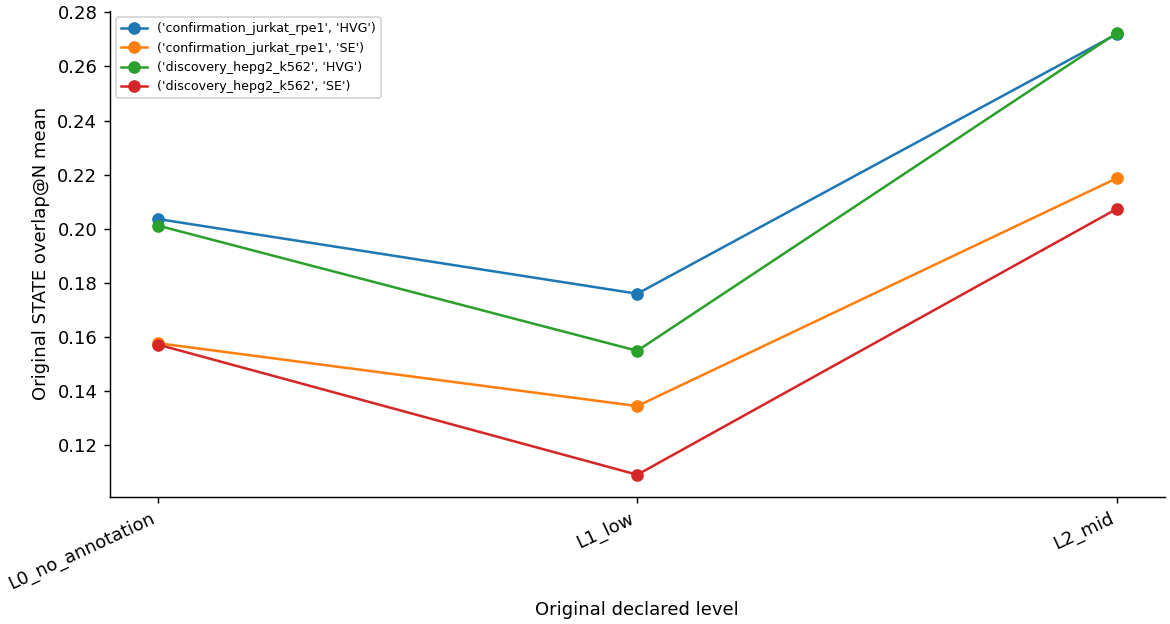

Curves are recalculated means under the original grouping rule. No new confidence bands have been added.


In [5]:
curve=ns.compare_curve('spc_replogle_fewshot_reactome_support.csv', initial=False)
ns.show_curve(curve)

## Original agent decision and supporting diagnostics

The following records preserve the agent’s actual determination, including rejected candidates and controls. Their historical status labels are shown as recorded.

In [6]:
ns.display_json(rp.CONTINUED/'artifacts/auditor_decision_replogle_reactome_support.json')

```json
{
  "axis_id": "STATE_REPLOGLE_REACTOME_TRAIN_SUPPORT_V1",
  "decision": "valid",
  "issues": [],
  "closure_gate": {
    "prospective": true,
    "frozen_before_confirmation": true,
    "measured_similarity_order": "see spc_replogle_fewshot_reactome_support.csv",
    "confirmed_on_held_out_contexts": true,
    "baseline_context": "No raw labels/predictions were available in official result CSVs; fixed-label baseline cannot be rerun without raw matrices."
  }
}
```

All source files, downloaded inputs and historical outputs are checksummed in `original_manifest.json`. The full preliminary candidate screening and download inventory are retained in notebook `00-original-downloads-and-axis-history.ipynb`.